# Matching every product, and comparing prices

The model from `train.ipynb` is trained on all labels and run over every Coop product (10 ICA candidates each).
The matches it is confident about become a list of identical products sold in both stores, which is then used
to compare ICA and Coop prices.

Data: one snapshot per store, last seen late March 2026 (ICA) and early April 2026 (Coop).
Prices are averages over that period, and for ICA also across stores (each ICA store sets its own prices).

Labels in the test range of `labels/split.json` are a held-out test set: everything is developed on the other labels,
and the test set is only scored once, near the end.

In [1]:
# Setup: load normalized products, candidate pairs (from explore.ipynb) and labels (from labeler/)
import json
from difflib import SequenceMatcher
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold
from xgboost import XGBClassifier

products = pd.read_parquet("../data/products_normalized.parquet")
candidate_pairs = pd.read_parquet("../data/candidate_pairs.parquet")

# dtype=str: otherwise pandas turns EAN codes into integers and drops leading zeros
labels = pd.read_json("../labels/labels.jsonl", lines=True, dtype={"coop_key": str})
labels = labels.drop_duplicates("coop_key", keep="last")  # latest answer wins if you relabeled

# Held-out test set: labels in the order range of labels/split.json
split = json.loads(Path("../labels/split.json").read_text())
is_test = labels["order"].between(split["test_from_order"], split["test_to_order"] - 1)
labels, test_labels = labels[~is_test], labels[is_test]

# From the raw exports only product_type is needed: weighed products are priced per kg at Coop but per piece at ICA
product_types = pd.concat([
    pd.read_parquet(f"../data/{table}_products_2026-10-20.parquet", columns=["product_key", "product_type"])
    for table in ["public", "coop"]
])
print(pd.DataFrame({"dev": labels["status"].value_counts(), "test": test_labels["status"].value_counts()}).fillna(0).astype(int))

        dev  test
status           
match   171     0
none    110     0
skip     20     0


In [2]:
# One row per (Coop product, shown ICA candidate), y = 1 if you selected it. Skipped products are left out.
def label_pairs(labels):
    labeled = labels[labels["status"].isin(["match", "none"])]
    pairs = (
        labeled[["coop_key", "shown", "matches"]]
        .explode("shown")
        .rename(columns={"shown": "ica_key"})
        .merge(candidate_pairs[["coop_key", "ica_key", "rank", "score"]], on=["coop_key", "ica_key"], how="left")
    )
    pairs["y"] = [ica in matches for ica, matches in zip(pairs["ica_key"], pairs["matches"])]
    pairs["y"] = pairs["y"].astype(int)
    pairs = pairs.drop(columns="matches")

    # If candidate_pairs was regenerated after labeling, some shown pairs may be missing a score
    assert pairs["score"].notna().all(), "candidate_pairs.parquet changed since labeling"
    return pairs

pairs, test_pairs = label_pairs(labels), label_pairs(test_labels)
for name, df in [("dev", pairs), ("test", test_pairs)]:
    print(f"{name}: {len(df):,} pairs, {df['y'].sum()} positives, {df['coop_key'].nunique()} Coop products")

dev: 2,810 pairs, 175 positives, 281 Coop products
test: 0 pairs, 0 positives, 0 Coop products


In [3]:
# Pair features (same as train.ipynb)
INFO = ["product_key", "name", "brand_norm", "name_norm", "size_value", "size_unit", "price"]
coop_info = products[products["store"] == "coop"][INFO].add_prefix("coop_")
ica_info = products[products["store"] == "ica"][INFO].add_prefix("ica_")

def similarity(a, b):
    return SequenceMatcher(None, a, b).ratio()

def jaccard(a, b):
    a, b = set(a.split()), set(b.split())
    return len(a & b) / len(a | b) if a | b else 0.0

def add_features(df):
    df = (
        df.merge(coop_info, left_on="coop_key", right_on="coop_product_key")
          .merge(ica_info, left_on="ica_key", right_on="ica_product_key")
    )
    # How this candidate compares to the best TF-IDF candidate for the same Coop product
    df["score_gap"] = df.groupby("coop_key")["score"].transform("max") - df["score"]

    df["brand_equal"] = (df["coop_brand_norm"] == df["ica_brand_norm"]).astype(int)
    df["brand_sim"] = [similarity(a, b) for a, b in zip(df["coop_brand_norm"], df["ica_brand_norm"])]
    df["name_sim"] = [similarity(a, b) for a, b in zip(df["coop_name_norm"], df["ica_name_norm"])]
    df["name_jaccard"] = [jaccard(a, b) for a, b in zip(df["coop_name_norm"], df["ica_name_norm"])]

    # Size and price: NaN when unknown, xgboost handles missing values itself
    same_unit = df["coop_size_unit"] == df["ica_size_unit"]
    df["same_unit"] = np.where(df["coop_size_unit"].isna() | df["ica_size_unit"].isna(), np.nan, same_unit)
    sizes = df[["coop_size_value", "ica_size_value"]].where(same_unit, axis=0)
    df["size_ratio"] = sizes.min(axis=1) / sizes.max(axis=1)
    prices = df[["coop_price", "ica_price"]]
    df["price_ratio"] = prices.min(axis=1) / prices.max(axis=1)
    return df

FEATURES = [
    "score", "rank", "score_gap",
    "brand_equal", "brand_sim", "name_sim", "name_jaccard",
    "same_unit", "size_ratio", "price_ratio",
]

pairs = add_features(pairs)
test_pairs = add_features(test_pairs) if len(test_pairs) else test_pairs

In [4]:
# Product-level evaluation (same as train.ipynb): per Coop product, take the best candidate if its score >= threshold, else "none".
# precision = predicted matches that are right, recall = real matches found,
# accuracy = products fully right (a "none" product counts as right when nothing is predicted)
def evaluate(df, score_col, threshold):
    # ties (e.g. ICA duplicates with the same score) go to the better TF-IDF rank
    best = df.sort_values([score_col, "rank"], ascending=[False, True]).groupby("coop_key").head(1)
    has_match = df.groupby("coop_key")["y"].max()
    predicted = best[best[score_col] >= threshold]

    correct = predicted["y"].sum()
    n_predicted, n_real = len(predicted), has_match.sum()
    n_correct_none = ((has_match == 0) & ~has_match.index.isin(predicted["coop_key"])).sum()
    return {
        "precision": correct / n_predicted if n_predicted else 0.0,
        "recall": correct / n_real,
        "accuracy": (correct + n_correct_none) / len(has_match),
        "threshold": threshold,
    }

def best_threshold(df, score_col, metric="accuracy"):
    results = [evaluate(df, score_col, t) for t in np.arange(0, 1.0, 0.05)]
    return max(results, key=lambda r: r[metric])

def bootstrap_interval(df, score_col, threshold, n=2000, seed=0):
    # 95% interval for precision and recall, from resampling the Coop products with replacement
    best = df.sort_values([score_col, "rank"], ascending=[False, True]).groupby("coop_key").head(1).set_index("coop_key")
    predicted = (best[score_col] >= threshold).to_numpy()
    correct = predicted & (best["y"] == 1).to_numpy()
    real = df.groupby("coop_key")["y"].max().reindex(best.index).to_numpy() == 1
    idx = np.random.default_rng(seed).integers(0, len(best), (n, len(best)))
    return {
        "precision": np.percentile(correct[idx].sum(1) / np.maximum(predicted[idx].sum(1), 1), [2.5, 97.5]),
        "recall": np.percentile(correct[idx].sum(1) / np.maximum(real[idx].sum(1), 1), [2.5, 97.5]),
    }

In [5]:
# The model in train.ipynb uses price_ratio, so it prefers candidates with a similar price.
# That would hide real price differences in the comparison below, so here the model is trained without it.
# Cross-validated like train.ipynb (5 folds grouped by Coop product), to see what leaving price out costs.
FEATURES_NO_PRICE = [f for f in FEATURES if f != "price_ratio"]

def make_model():
    return XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=0)

def cv_predict(features):
    prob = pd.Series(np.nan, index=pairs.index)
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
    for train_idx, test_idx in cv.split(pairs, pairs["y"], groups=pairs["coop_key"]):
        model = make_model().fit(pairs.iloc[train_idx][features], pairs.iloc[train_idx]["y"])
        prob.iloc[test_idx] = model.predict_proba(pairs.iloc[test_idx][features])[:, 1]
    return prob

pairs["prob_with_price"] = cv_predict(FEATURES)
pairs["prob"] = cv_predict(FEATURES_NO_PRICE)
pd.DataFrame({
    "with price_ratio": evaluate(pairs, "prob_with_price", 0.5),
    "without price_ratio": evaluate(pairs, "prob", 0.5),
}).T.round(3)

,precision,recall,accuracy,threshold
with price_ratio,0.884,0.760,0.822,0.5
without price_ratio,0.871,0.749,0.815,0.5


In [6]:
# Threshold: a wrong match adds a fake price difference to the comparison, so aim for >= 90% precision.
# It is picked on the same cross-validated predictions it is scored on, so this estimate is slightly optimistic
# (the test set below gives the honest number).
TARGET_PRECISION = 0.9
thresholds = pd.DataFrame([evaluate(pairs, "prob", t) for t in np.arange(0.05, 1.0, 0.05).round(2)])
THRESHOLD = thresholds.loc[thresholds["precision"] >= TARGET_PRECISION, "threshold"].min()
cv_result = evaluate(pairs, "prob", THRESHOLD)
print(f"threshold {THRESHOLD}:", {k: round(float(v), 3) for k, v in cv_result.items()})
thresholds.round(3)

threshold 0.8: {'precision': 0.933, 'recall': 0.567, 'accuracy': 0.73, 'threshold': 0.8}


,precision,recall,accuracy,threshold
0,0.734,0.871,0.804,0.05
1,0.775,0.865,0.826,0.10
2,0.775,0.848,0.815,0.15
3,0.789,0.830,0.815,0.20
4,0.800,0.795,0.808,0.25
5,0.813,0.789,0.808,0.30
6,0.832,0.784,0.819,0.35
7,0.843,0.784,0.826,0.40
8,0.863,0.772,0.822,0.45
9,0.871,0.749,0.815,0.50


In [7]:
# Held-out test set: scored once, with the model, features and threshold fixed on the dev labels above.
# The TF-IDF baseline gets its threshold tuned on the dev labels too.
if test_pairs.empty:
    print(f"No test labels yet: label products {split['test_from_order']}-{split['test_to_order'] - 1} "
          "in labeler/ and rerun. Until then the estimates below use the cross-validated numbers.")
    result = cv_result
else:
    dev_model = make_model().fit(pairs[FEATURES_NO_PRICE], pairs["y"])
    test_pairs["prob"] = dev_model.predict_proba(test_pairs[FEATURES_NO_PRICE])[:, 1]
    result = evaluate(test_pairs, "prob", THRESHOLD)
    interval = bootstrap_interval(test_pairs, "prob", THRESHOLD)
    print(f"{test_pairs['coop_key'].nunique()} test products, 95% intervals: "
          + ", ".join(f"{m} {lo:.2f}-{hi:.2f}" for m, (lo, hi) in interval.items()))
    display(pd.DataFrame({
        "TF-IDF baseline": evaluate(test_pairs, "score", best_threshold(pairs, "score")["threshold"]),
        "XGBoost": result,
        "XGBoost (cross-validated on dev)": cv_result,
    }).T.round(3))

No test labels yet: label products 301-500 in labeler/ and rerun. Until then the estimates below use the cross-validated numbers.


In [8]:
# Train on all labels (dev + test, now that the test set is scored) and score every candidate pair:
# 10 ICA candidates for each Coop product
all_labeled = pd.concat([pairs, test_pairs]) if len(test_pairs) else pairs
model = make_model().fit(all_labeled[FEATURES_NO_PRICE], all_labeled["y"])
all_pairs = add_features(candidate_pairs[["coop_key", "ica_key", "rank", "score"]])
all_pairs["prob"] = model.predict_proba(all_pairs[FEATURES_NO_PRICE])[:, 1]
print(f"{len(all_pairs):,} pairs scored for {all_pairs['coop_key'].nunique():,} Coop products")

268,140 pairs scored for 26,814 Coop products


In [9]:
# Per Coop product: the best ICA candidate, if it clears the threshold.
# One ICA listing can win for several Coop products (e.g. near-duplicate listings), so only the most confident is kept.
best = all_pairs.sort_values(["prob", "rank"], ascending=[False, True]).groupby("coop_key").head(1)
matches = best[best["prob"] >= THRESHOLD].drop_duplicates("ica_key")

# The labeled products are a random sample of all Coop products, so the test numbers carry over
# (the cross-validated ones until there are test labels)
n_coop = all_pairs["coop_key"].nunique()
precision, recall = result["precision"], result["recall"]
print(f"{len(matches):,} of {n_coop:,} Coop products matched ({len(matches) / n_coop:.0%})")
print(f"expected correct: ~{len(matches) * precision:,.0f} ({precision:.0%} precision)")
print(f"estimated real matches among the candidates: ~{len(matches) * precision / recall:,.0f} ({recall:.0%} recall)")

COLUMNS = [
    "coop_key", "ica_key", "prob",
    "coop_name", "ica_name", "coop_brand_norm", "ica_brand_norm",
    "coop_size_value", "coop_size_unit", "ica_size_value", "ica_size_unit",
    "coop_price", "ica_price",
]
matches = matches[COLUMNS].reset_index(drop=True)
matches.to_parquet("../data/matches.parquet", index=False)

8,589 of 26,814 Coop products matched (32%)
expected correct: ~8,011 (93% precision)
estimated real matches among the candidates: ~14,122 (57% recall)


In [10]:
# Spot check: a random sample of matches, from just above the threshold up to the sure ones
pd.set_option("display.max_colwidth", 45)
matches.sample(15, random_state=1).sort_values("prob")[
    ["prob", "coop_name", "ica_name", "coop_size_value", "ica_size_value", "coop_size_unit", "coop_price", "ica_price"]
].round(2)

,prob,coop_name,ica_name,coop_size_value,ica_size_value,coop_size_unit,coop_price,ica_price
7974,0.84,Ryggbiff Skivad 1-2 Skivor,Ryggbiff Skivad 1-2 Skivor ca 350g Gudruns,350.0,350.0,g,374.07,140.71
7867,0.84,Absolut Överens Pocket,Spel Absolut Överens pocket ALF,1.0,NaN,st,169.00,174.68
7504,0.85,Lättkorv 15%,Lättkorv 15% 400g Nordchark,400.0,400.0,g,52.01,51.44
7697,0.85,Läsk Loranga Zero,Läsk Loranga Zero 500ml Vasa Bryggeri,500.0,500.0,ml,15.45,15.23
7459,0.85,Kassler,Benfri kassler ca 800g Allmans,800.0,800.0,g,114.04,79.06
7314,0.85,Vem Där? Spel,Spel Vem där Hasbro,1.0,NaN,st,279.00,284.31
6729,0.88,Creamy Chicken,Kattgodis Creamy Chicken 4p Dreamies,4.0,4.0,st,19.71,20.21
6235,0.93,Lättmjölk,"Lättmjölk 0,5% 1l Wermlands Mejeri",1000.0,1000.0,ml,15.62,15.99
5830,0.94,Mjölkchoklad Chocolonely,Mjölkchoklad 180g Tony's Chocolonely,180.0,180.0,g,49.61,52.54
5712,0.94,Kalvlever Bit,Kalvlever ca 500g Scan,500.0,500.0,g,107.89,69.91


In [11]:
# Only matches where the two prices are for the same thing:
# - weighed products are left out (Coop gives a price per kg, ICA a price per piece)
# - the pack size must be known on both sides and equal (multipacks like '33cl 6-p' count as their total size)
# - prices more than 3x apart are left out as likely wrong matches or price errors (shown in the next cell)
MAX_PRICE_RATIO = 3
weighed = set(product_types.loc[product_types["product_type"].isin(["Vikt", "CATCHWEIGHT"]), "product_key"])
same_size = (
    (matches["coop_size_unit"] == matches["ica_size_unit"])
    & np.isclose(matches["coop_size_value"], matches["ica_size_value"], rtol=0.01)
)
price_ratio = matches["ica_price"] / matches["coop_price"]

steps = {
    "matched": pd.Series(True, index=matches.index),
    "not weighed": ~matches["coop_key"].isin(weighed) & ~matches["ica_key"].isin(weighed),
    "same known pack size": same_size,
    f"prices within {MAX_PRICE_RATIO}x": price_ratio.between(1 / MAX_PRICE_RATIO, MAX_PRICE_RATIO),
}
keep = pd.Series(True, index=matches.index)
funnel = {}
for step, mask in steps.items():
    keep &= mask
    funnel[step] = keep.sum()
compare = matches[keep].copy()
pd.Series(funnel, name="products")

matched                 8589
not weighed             8144
same known pack size    8101
prices within 3x        8096
Name: products, dtype: int64

In [12]:
# The ones left out for a too large price gap: worth a look, it's mostly wrong matches or price errors
outliers = matches[steps["not weighed"] & same_size & ~steps[f"prices within {MAX_PRICE_RATIO}x"]]
print(f"{len(outliers)} left out")
outliers[["coop_name", "ica_name", "coop_size_value", "coop_size_unit", "coop_price", "ica_price"]].head(10).round(2)

5 left out


,coop_name,ica_name,coop_size_value,coop_size_unit,coop_price,ica_price
636,Rödbeta Detroit 2 Rund Organic,Rödbeta Detroit 2 Rund 1-p Nelson Garden,1.0,st,39.93,8.84
2586,Ögonbrynsfärg Brun,Ögonbrynsfärg Brun 1-p Depend,1.0,st,15.95,95.39
5207,Al Capone Flame filter 10-pack,Al Capone Flame Filter 10 10-p,10.0,st,519.00,55.48
6048,Moods Flame Filter,Ritmeester Moods Flame Filter 10 Limpa,10.0,st,73.02,740.00
7319,Vårlök Akleja Blandade Färger,Aster Enkel blandade färger 1-p Nelson Ga...,1.0,st,59.90,8.38


In [13]:
# Price difference per product: +10% means the product costs 10% more at ICA than at Coop.
# Within +-2.5% counts as the same price (the middle bar in the chart below).
SAME_PRICE = 0.025
compare["diff"] = compare["ica_price"] / compare["coop_price"] - 1
compare["cheaper"] = np.select(
    [compare["diff"] > SAME_PRICE, compare["diff"] < -SAME_PRICE], ["Coop", "ICA"], default="same"
)
shares = compare["cheaper"].value_counts(normalize=True)
ica_total, coop_total = compare["ica_price"].sum(), compare["coop_price"].sum()

print(f"{len(compare):,} identical products with comparable prices")
print(f"cheaper at Coop: {shares.get('Coop', 0):.0%}, cheaper at ICA: {shares.get('ICA', 0):.0%}, same price (+-2.5%): {shares.get('same', 0):.0%}")
print(f"median difference: {compare['diff'].median():+.1%} (ICA vs Coop)")
print(f"one of each product: {ica_total:,.0f} kr at ICA vs {coop_total:,.0f} kr at Coop ({ica_total / coop_total - 1:+.1%})")
print(f"median gap where Coop is cheaper: {compare.loc[compare['cheaper'] == 'Coop', 'diff'].median():+.1%}, "
      f"where ICA is cheaper: {compare.loc[compare['cheaper'] == 'ICA', 'diff'].median():+.1%}")

8,096 identical products with comparable prices
cheaper at Coop: 49%, cheaper at ICA: 24%, same price (+-2.5%): 27%
median difference: +2.4% (ICA vs Coop)
one of each product: 389,666 kr at ICA vs 383,962 kr at Coop (+1.5%)
median gap where Coop is cheaper: +6.2%, where ICA is cheaper: -7.0%


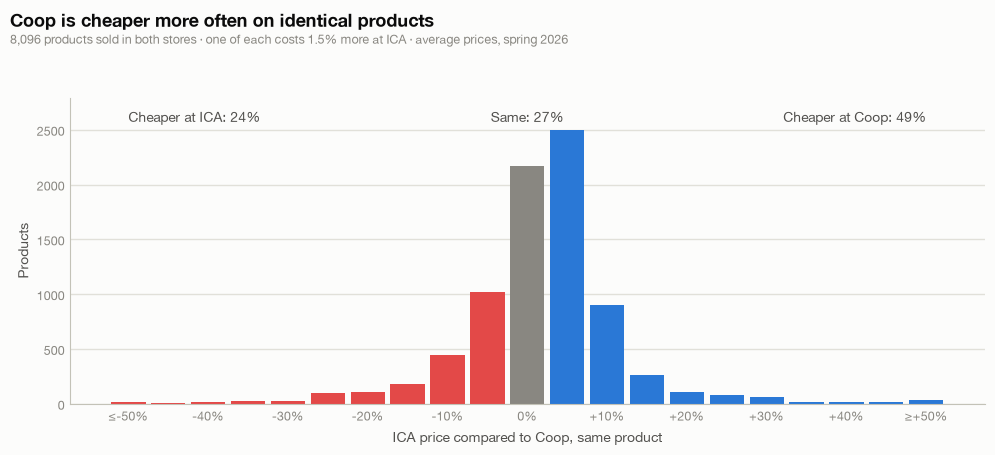

In [14]:
# Chart tokens (light surface, same as results.ipynb). Diverging: one hue per store, gray for the same price.
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
COOP_CHEAPER, ICA_CHEAPER, SAME_COLOR = "#2a78d6", "#e34948", "#898781"
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica Neue", "Arial", "DejaVu Sans"]

# 5% wide bins centered on 0 (so the middle bin is exactly the same-price band), beyond +-50% goes into the outer bins
BIN, LIMIT = 2 * SAME_PRICE, 0.5
centers = np.arange(-LIMIT, LIMIT + BIN / 2, BIN).round(2)
binned = (compare["diff"].clip(-LIMIT, LIMIT) / BIN).round().astype(int) * BIN
counts = binned.round(2).value_counts().reindex(centers, fill_value=0)
colors = [SAME_COLOR if c == 0 else COOP_CHEAPER if c > 0 else ICA_CHEAPER for c in centers]

fig, ax = plt.subplots(figsize=(10, 4.6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.bar(centers, counts, width=BIN * 0.86, color=colors, linewidth=0)

# Direct labels on each side instead of a legend
top = counts.max()
for x, ha, store in [(-LIMIT, "left", "ICA"), (LIMIT, "right", "Coop")]:
    ax.text(x, top * 1.02, f"Cheaper at {store}: {shares.get(store, 0):.0%}", ha=ha, va="bottom", fontsize=10, color=INK_2)
ax.text(0, top * 1.02, f"Same: {shares.get('same', 0):.0%}", ha="center", va="bottom", fontsize=10, color=INK_2)

ticks = np.arange(-LIMIT, LIMIT + 0.01, 0.1).round(1)
ax.set_xticks(ticks)
ax.set_xticklabels(["0%" if t == 0 else f"{t:+.0%}" if abs(t) < LIMIT else f"{'≤' if t < 0 else '≥'}{t:+.0%}" for t in ticks])
ax.set_xlabel("ICA price compared to Coop, same product", fontsize=10, color=INK_2)
ax.set_ylabel("Products", fontsize=10, color=INK_2)
ax.set_ylim(0, top * 1.12)
ax.grid(axis="y", color=GRID, lw=1)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(AXIS)
ax.tick_params(colors=MUTED, labelsize=9, length=0)

cheaper_store = "Coop" if shares.get("Coop", 0) > shares.get("ICA", 0) else "ICA"
fig.suptitle(f"{cheaper_store} is cheaper more often on identical products", x=0.01, ha="left", fontsize=13, color=INK, fontweight="bold")
basket_gap = ica_total / coop_total - 1
fig.text(0.01, 0.905, f"{len(compare):,} products sold in both stores · one of each costs {abs(basket_gap):.1%} "
         f"{'more' if basket_gap > 0 else 'less'} at ICA · average prices, spring 2026", fontsize=9, color=MUTED)
fig.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

In [15]:
# Brands with the most matched products: does one store win across the board, or brand by brand?
brands = (
    compare.groupby("coop_brand_norm")
    .agg(products=("diff", "size"), median_diff=("diff", "median"),
         cheaper_at_coop=("cheaper", lambda s: (s == "Coop").mean()),
         cheaper_at_ica=("cheaper", lambda s: (s == "ICA").mean()))
    .sort_values("products", ascending=False)
    .head(15)
)
brands.round(2)

,products,median_diff,cheaper_at_coop,cheaper_at_ica
coop_brand_norm,,,,
nelsongarden,198,-0.17,0.06,0.89
santamaria,136,0.04,0.63,0.04
zeta,106,0.04,0.62,0.09
felix,89,0.03,0.61,0.03
bonjour,80,0.09,0.71,0.18
happyparty,71,0.00,0.14,0.08
nyhlenshugosons,67,-0.02,0.18,0.45
norrmejerier,64,0.01,0.36,0.17
fazer,63,0.03,0.63,0.05
